<div align="center">

# МГТУ им. Н.Э. Баумана

### Факультет «Информатика и системы управления» (ИУ)
### Кафедра «Информационные системы и телекоммуникации» (ИУ3)

# Отчёт по лабораторной работе №9
## по курсу «Технологии машинного обучения»

### Тема: Анализ и прогнозирование временного ряда

</div>

---

**Выполнил:** Суржиков Лев Алексеевич

**Группа:** ИУ3С-51Б

**Проверил:** Ю.Е. Гапанюк

## 1. Описание задания

**Цель работы:** изучение основных методов анализа и прогнозирования временных рядов.

**Задание:**
1. Выбрать набор данных для решения задачи прогнозирования временного ряда.
2. Визуализировать временной ряд и его основные характеристики.
3. Разделить временной ряд на обучающую и тестовую выборку.
4. Выполнить прогнозирование следующими методами: одним из авторегрессионных методов (ARMA, ARIMA, ...); методом символьной регрессии; двумя методами из семейства МГУА (один линейный COMBI/MULTI и один нелинейный MIA/RIA) с использованием библиотеки gmdh.
5. Визуализировать тестовую выборку и каждый из прогнозов.
6. Оценить качество прогноза в каждом случае с помощью подходящей метрики.
7. (Дополнительно) оставить обратную связь по использованию библиотеки gmdh.

Ссылка на постановку задания: https://github.com/ugapanyuk/courses_current/wiki/LAB_TMO_TIMESERIES

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import warnings

from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from gplearn.genetic import SymbolicRegressor
import gmdh

matplotlib.rcParams["font.family"] = "DejaVu Sans"
matplotlib.rcParams["axes.unicode_minus"] = False
warnings.filterwarnings("ignore")

BLUE_DARK = "#1B3B6F"
BLUE = "#3B6EA5"
BLUE_LIGHT = "#8FB8D9"
RED_DARK = "#7A1F2B"
RED = "#B23A48"
RED_LIGHT = "#E0949C"

## 2. Набор данных

Используется набор данных **Air Passengers** (международные авиаперевозки пассажиров) — классический временной ряд, размещённый на платформе Kaggle (https://www.kaggle.com/datasets/rakannimer/air-passengers) и сохранённый в файле `air_passengers.csv`. Ряд содержит число пассажиров (в тысячах) по месяцам с января 1949 по декабрь 1960 года — 144 значения. В ряду есть растущий тренд и годовая сезонность, амплитуда которой растёт вместе с уровнем.

In [2]:
data = pd.read_csv("air_passengers.csv", parse_dates=["month"], index_col="month")
series = data["passengers"].asfreq("MS")
print("Значений:", len(series), " пропусков:", series.isna().sum(), " период:", series.index[0].strftime("%m.%Y"), "—", series.index[-1].strftime("%m.%Y"))
series.head()

Значений: 144  пропусков: 0  период: 01.1949 — 12.1960


month
1949-01-01    112
1949-02-01    118
1949-03-01    132
1949-04-01    129
1949-05-01    121
Freq: MS, Name: passengers, dtype: int64

## 3. Визуализация временного ряда и его характеристик

### 3.1. Ряд и скользящие статистики

Скользящее среднее (окно 12 месяцев) показывает тренд, скользящее стандартное отклонение — изменчивость.

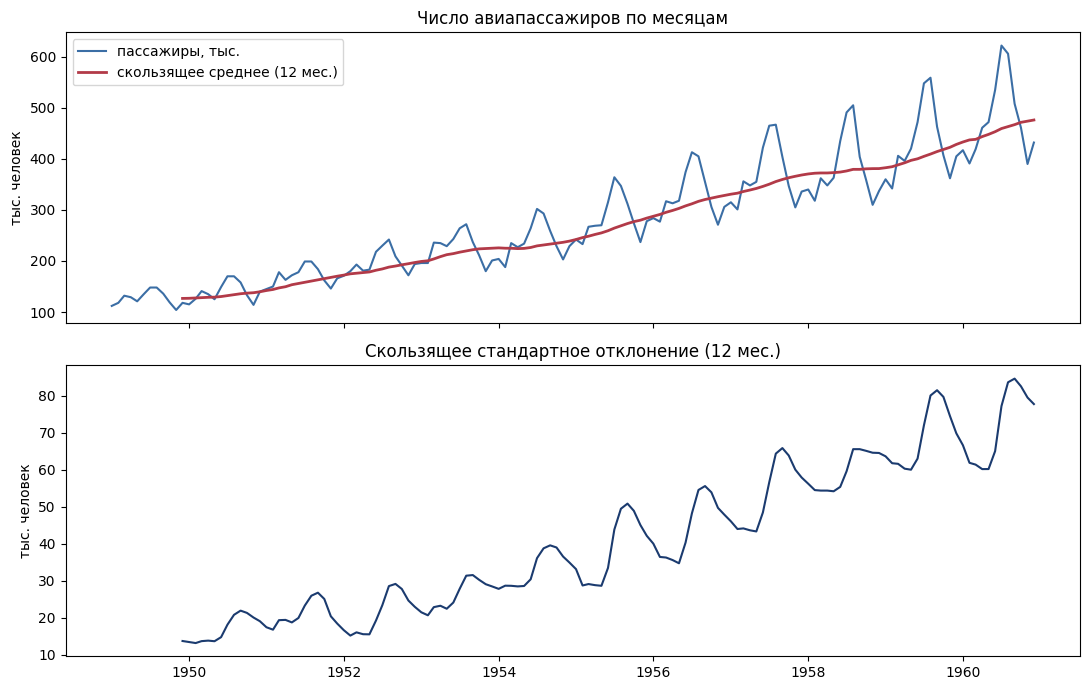

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(series, color=BLUE, linewidth=1.5, label="пассажиры, тыс.")
axes[0].plot(series.rolling(12).mean(), color=RED, linewidth=2, label="скользящее среднее (12 мес.)")
axes[0].set_ylabel("тыс. человек")
axes[0].set_title("Число авиапассажиров по месяцам")
axes[0].legend()
axes[1].plot(series.rolling(12).std(), color=BLUE_DARK)
axes[1].set_ylabel("тыс. человек")
axes[1].set_title("Скользящее стандартное отклонение (12 мес.)")
plt.tight_layout()
plt.show()

### 3.2. Сезонность

Сравним среднее число пассажиров по календарным месяцам: пик приходится на лето.

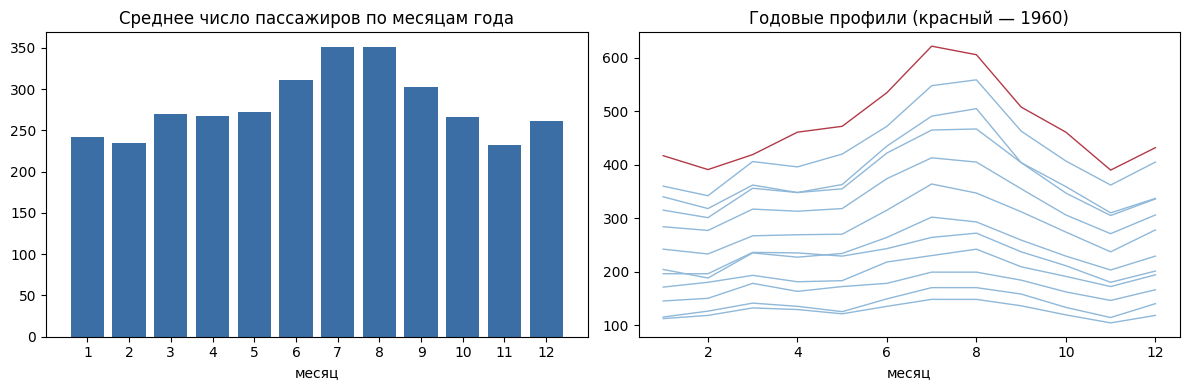

In [4]:
seasonal = series.groupby(series.index.month).mean()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(seasonal.index, seasonal.values, color=BLUE)
axes[0].set_xticks(range(1, 13))
axes[0].set_title("Среднее число пассажиров по месяцам года")
axes[0].set_xlabel("месяц")
for year, g in series.groupby(series.index.year):
    axes[1].plot(g.index.month, g.values, color=BLUE_LIGHT if year < 1960 else RED, linewidth=1)
axes[1].set_title("Годовые профили (красный — 1960)")
axes[1].set_xlabel("месяц")
plt.tight_layout()
plt.show()

### 3.3. Преобразование ряда, стационарность и автокорреляция

Амплитуда колебаний растёт вместе с уровнем, поэтому берём **логарифм** ряда: это делает размах сезонности постоянным. Затем убираем тренд первой разностью. Стационарность проверяем тестом Дики–Фуллера (ADF): если p-value больше 0,05, ряд нестационарен.

In [5]:
log_series = np.log(series)
diff1 = log_series.diff().dropna()                   # убран тренд
diff12 = log_series.diff().diff(12).dropna()         # убраны тренд и сезонность

def adf_report(name, x):
    stat, p = adfuller(x)[:2]
    print(f"{name}: статистика {stat:.3f}, p-value {p:.4f} ->", "стационарен" if p < 0.05 else "нестационарен")

adf_report("Исходный ряд", series)
adf_report("Логарифм", log_series)
adf_report("Разность логарифма (d=1)", diff1)
adf_report("Разность + сезонная разность (d=1, D=1)", diff12)

Исходный ряд: статистика 0.815, p-value 0.9919 -> нестационарен
Логарифм: статистика -1.717, p-value 0.4224 -> нестационарен
Разность логарифма (d=1): статистика -2.717, p-value 0.0711 -> нестационарен
Разность + сезонная разность (d=1, D=1): статистика -4.443, p-value 0.0002 -> стационарен


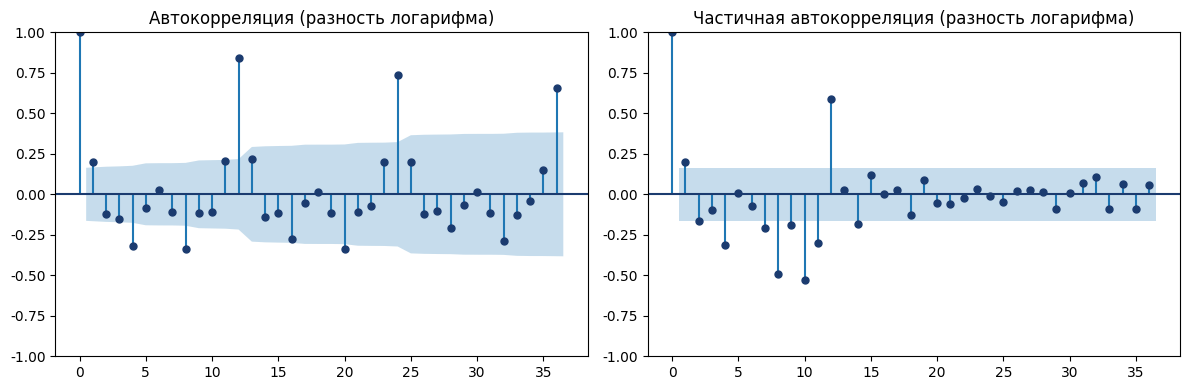

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(diff1, lags=36, ax=axes[0], color=BLUE_DARK)
plot_pacf(diff1, lags=36, ax=axes[1], color=BLUE_DARK, method="ywm")
axes[0].set_title("Автокорреляция (разность логарифма)")
axes[1].set_title("Частичная автокорреляция (разность логарифма)")
plt.tight_layout()
plt.show()

Пики на лагах 12, 24, 36 подтверждают годовую сезонность.

## 4. Разделение на обучающую и тестовую выборки

Для временного ряда данные нельзя перемешивать: тестовой берём **последние 24 месяца** (1959–1960 годы), остальное — обучающая выборка. Все модели прогнозируют сразу весь тестовый период (24 шага вперёд).

Обучающая выборка: 120 месяцев, до 12.1958
Тестовая выборка: 24 месяцев, с 01.1959


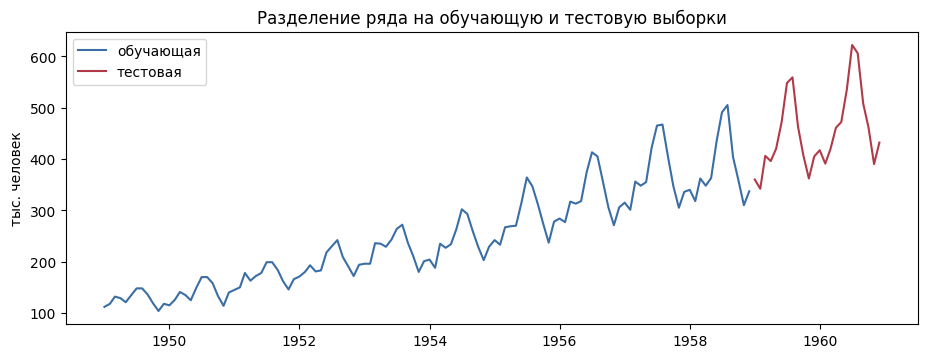

In [7]:
test_size = 24
train, test = series.iloc[:-test_size], series.iloc[-test_size:]
print("Обучающая выборка:", len(train), "месяцев, до", train.index[-1].strftime("%m.%Y"))
print("Тестовая выборка:", len(test), "месяцев, с", test.index[0].strftime("%m.%Y"))

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(train, color=BLUE, label="обучающая")
ax.plot(test, color=RED, label="тестовая")
ax.set_title("Разделение ряда на обучающую и тестовую выборки")
ax.set_ylabel("тыс. человек")
ax.legend()
plt.show()

## 5. Прогнозирование

Метрики качества: **MAE** (средняя абсолютная ошибка, тыс. человек), **RMSE** и **MAPE** (средняя абсолютная процентная ошибка). Для сравнения добавлен **сезонный наивный прогноз** — «каждый месяц будет таким же, как год назад». Хорошая модель должна его превзойти.

### 5.1. Авторегрессионный метод: SARIMA

Используем сезонную модель ARIMA(p, 1, q)(P, 1, Q)₁₂ по логарифму ряда: обычная и сезонная разности убирают тренд и сезонность. Порядки p, q, P, Q перебираем от 0 до 1 по критерию Акаике (AIC).

In [8]:
def metrics(y_true, y_pred):
    err = np.asarray(y_true) - np.asarray(y_pred)
    return {"MAE": np.mean(np.abs(err)),
            "RMSE": np.sqrt(np.mean(err ** 2)),
            "MAPE, %": np.mean(np.abs(err / np.asarray(y_true))) * 100}

log_train = np.log(train.values)
best = None
for p in range(2):
    for q in range(2):
        for P in range(2):
            for Q in range(2):
                fit = SARIMAX(log_train, order=(p, 1, q), seasonal_order=(P, 1, Q, 12)).fit(disp=False)
                print(f"SARIMA({p},1,{q})({P},1,{Q})12: AIC {fit.aic:.1f}")
                if best is None or fit.aic < best[0]:
                    best = (fit.aic, (p, 1, q, P, 1, Q), fit)
print("Выбрана модель SARIMA%s" % (best[1],))

pred_arima = np.exp(best[2].forecast(test_size))
pred_naive = train.values[-12:][np.arange(test_size) % 12]       # сезонный наивный: значения года назад
results = {"SARIMA": metrics(test, pred_arima), "Сезонный наивный прогноз": metrics(test, pred_naive)}
print({k: round(v, 3) for k, v in results["SARIMA"].items()})

SARIMA(0,1,0)(0,1,0)12: AIC -353.4


SARIMA(0,1,0)(0,1,1)12: AIC -380.0
SARIMA(0,1,0)(1,1,0)12: AIC -371.5
SARIMA(0,1,0)(1,1,1)12: AIC -378.0


SARIMA(0,1,1)(0,1,0)12: AIC -364.3


SARIMA(0,1,1)(0,1,1)12: AIC -389.0


SARIMA(0,1,1)(1,1,0)12: AIC -384.2


SARIMA(0,1,1)(1,1,1)12: AIC -387.2


SARIMA(1,1,0)(0,1,0)12: AIC -363.6
SARIMA(1,1,0)(0,1,1)12: AIC -388.6
SARIMA(1,1,0)(1,1,0)12: AIC -383.4


SARIMA(1,1,0)(1,1,1)12: AIC -386.8
SARIMA(1,1,1)(0,1,0)12: AIC -362.6
SARIMA(1,1,1)(0,1,1)12: AIC -386.7


SARIMA(1,1,1)(1,1,0)12: AIC -382.3


SARIMA(1,1,1)(1,1,1)12: AIC -385.4
Выбрана модель SARIMA(0, 1, 1, 0, 1, 1)
{'MAE': 39.445, 'RMSE': 43.182, 'MAPE, %': 8.516}


### 5.2. Подготовка признаков для моделей на основе лагов

Символьная регрессия и методы МГУА работают с таблицей «признаки → целевое значение». Превращаем ряд в такую таблицу: признаки — 12 предыдущих значений **разности логарифма** (охватывают целый год, поэтому видят сезонность), целевое значение — следующее. Многошаговый прогноз получаем рекурсивно: предсказанное значение добавляем в историю и предсказываем следующее, затем накапливаем разности и возвращаемся от логарифма к исходным единицам.

In [9]:
lags = 12
diff_train = np.diff(log_train)
X, Y = gmdh.time_series_transformation(diff_train, lags)
print("Матрица признаков:", X.shape, " Целевые значения:", Y.shape)

def forecast_recursive(model, history_diff, steps, last_log_level):
    window = list(history_diff[-lags:])
    diffs = []
    for _ in range(steps):
        d = float(np.ravel(model.predict(np.array(window[-lags:]).reshape(1, -1)))[0])
        diffs.append(d)
        window.append(d)
    return np.exp(last_log_level + np.cumsum(diffs))

Матрица признаков: (107, 12)  Целевые значения: (107,)


### 5.3. Метод символьной регрессии

Символьная регрессия (gplearn) эволюционным способом подбирает **формулу** (из операций сложения, вычитания и умножения), которая лучше всего предсказывает следующее значение по предыдущим.

In [10]:
sym = SymbolicRegressor(population_size=2000, generations=30, function_set=("add", "sub", "mul"),
                        parsimony_coefficient=0.001, metric="mse", random_state=1, n_jobs=1)
sym.fit(X, Y)
print("Найденная формула:", sym._program)

pred_sym = forecast_recursive(sym, diff_train, test_size, log_train[-1])
results["Символьная регрессия"] = metrics(test, pred_sym)
print({k: round(v, 3) for k, v in results["Символьная регрессия"].items()})

Найденная формула: X0
{'MAE': 69.547, 'RMSE': 75.213, 'MAPE, %': 15.153}


### 5.4. Методы МГУА (библиотека gmdh)

Метод группового учёта аргументов (МГУА) строит модель из простых полиномов и отбирает лучшие по внешнему критерию (на отложенной части данных). Берём два метода:
- **COMBI** — линейный комбинаторный метод: перебирает комбинации лагов и строит линейную модель;
- **RIA** — нелинейный (полиномиальный) метод: строит многоуровневую сеть квадратичных полиномов.

In [11]:
combi = gmdh.Combi()
combi.fit(X, Y)
pred_combi = forecast_recursive(combi, diff_train, test_size, log_train[-1])
results["МГУА: COMBI (линейный)"] = metrics(test, pred_combi)
print({k: round(v, 3) for k, v in results["МГУА: COMBI (линейный)"].items()})

{'MAE': 19.485, 'RMSE': 22.686, 'MAPE, %': 4.308}


In [12]:
ria = gmdh.Ria()
ria.fit(X, Y)
pred_ria = forecast_recursive(ria, diff_train, test_size, log_train[-1])
results["МГУА: RIA (нелинейный)"] = metrics(test, pred_ria)
print({k: round(v, 3) for k, v in results["МГУА: RIA (нелинейный)"].items()})

{'MAE': 76.914, 'RMSE': 83.54, 'MAPE, %': 16.741}


Для полноты проверим и два оставшихся метода МГУА (MULTI — линейный, MIA — нелинейный).

In [13]:
extra = {}
for name, model in [("MULTI (линейный)", gmdh.Multi()), ("MIA (нелинейный)", gmdh.Mia())]:
    model.fit(X, Y)
    extra[name] = metrics(test, forecast_recursive(model, diff_train, test_size, log_train[-1]))
pd.DataFrame(extra).T.round(3)

,MAE,RMSE,"MAPE, %"
MULTI (линейный),60.124,65.306,12.932
MIA (нелинейный),81.104,88.956,17.636


## 6. Визуализация прогнозов и сравнение качества

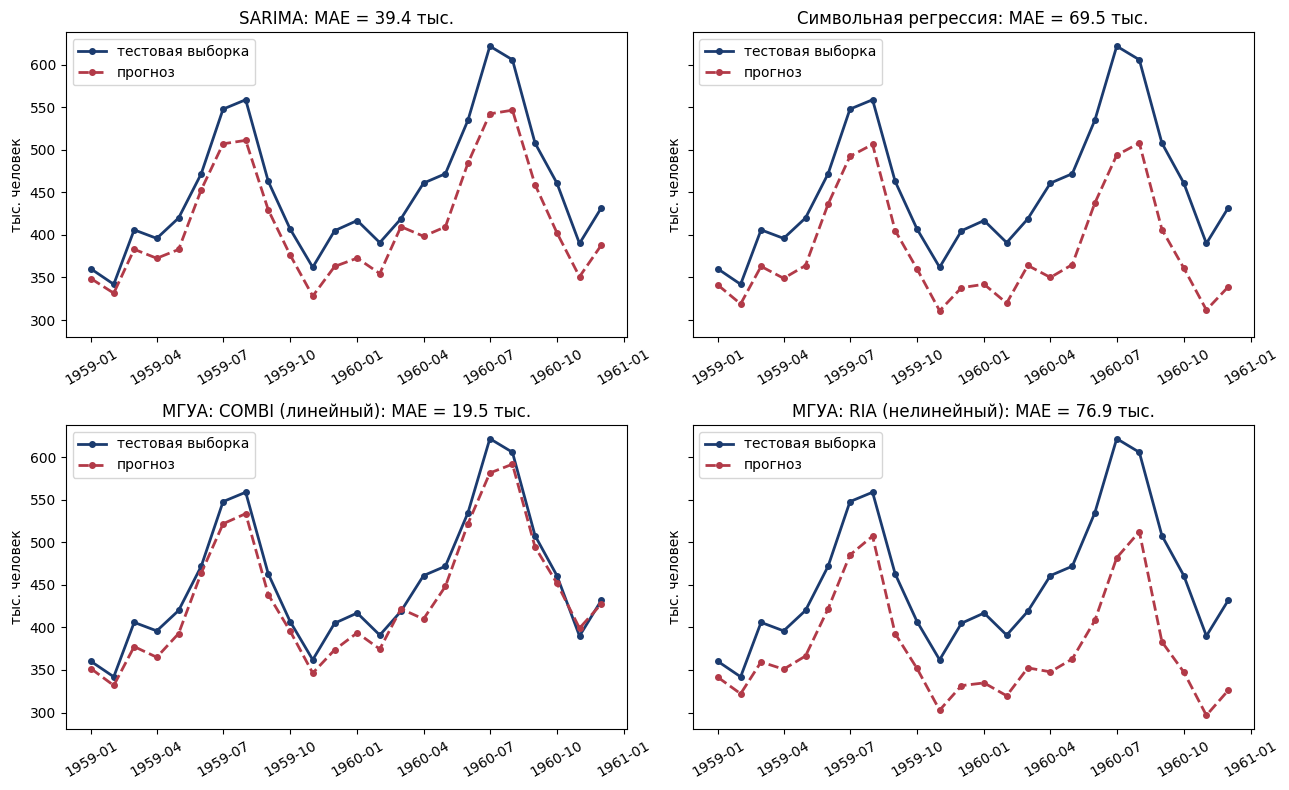

In [14]:
forecasts = {"SARIMA": pred_arima,
             "Символьная регрессия": pred_sym,
             "МГУА: COMBI (линейный)": pred_combi,
             "МГУА: RIA (нелинейный)": pred_ria}
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharey=True)
for ax, (name, fc) in zip(axes.ravel(), forecasts.items()):
    ax.plot(test.index, test.values, color=BLUE_DARK, linewidth=2, marker="o", markersize=4, label="тестовая выборка")
    ax.plot(test.index, fc, color=RED, linewidth=2, linestyle="--", marker="o", markersize=4, label="прогноз")
    ax.set_title(f"{name}: MAE = {results[name]['MAE']:.1f} тыс.")
    ax.set_ylabel("тыс. человек")
    ax.tick_params(axis="x", rotation=30)
    ax.legend()
plt.tight_layout()
plt.show()

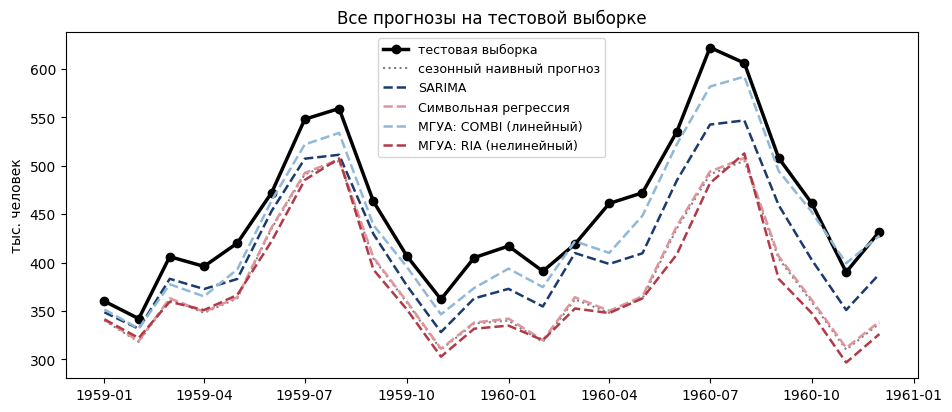

In [15]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(test.index, test.values, color="black", linewidth=2.5, marker="o", label="тестовая выборка")
ax.plot(test.index, pred_naive, color="grey", linewidth=1.5, linestyle=":", label="сезонный наивный прогноз")
for (name, fc), c in zip(forecasts.items(), [BLUE_DARK, RED_LIGHT, BLUE_LIGHT, RED]):
    ax.plot(test.index, fc, linewidth=1.8, linestyle="--", color=c, label=name)
ax.set_title("Все прогнозы на тестовой выборке")
ax.set_ylabel("тыс. человек")
ax.legend(fontsize=9)
plt.show()

In [16]:
table = pd.DataFrame(results).T.sort_values("MAE")
table.round(3)

,MAE,RMSE,"MAPE, %"
МГУА: COMBI (линейный),19.485,22.686,4.308
SARIMA,39.445,43.182,8.516
Символьная регрессия,69.547,75.213,15.153
Сезонный наивный прогноз,71.250,76.995,15.523
МГУА: RIA (нелинейный),76.914,83.540,16.741


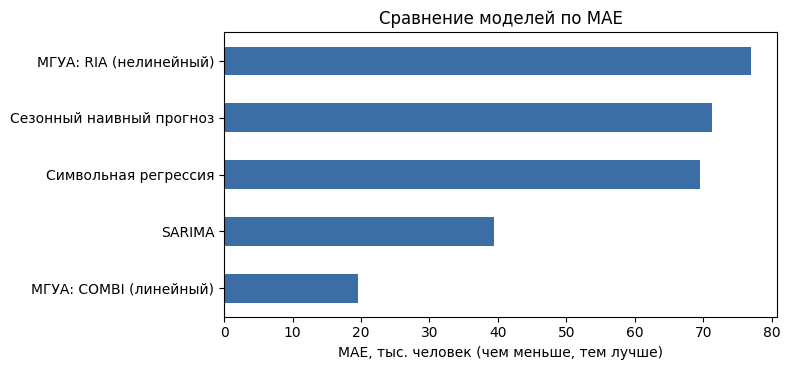

In [17]:
ax = table["MAE"].sort_values().plot(kind="barh", color=BLUE, figsize=(8, 3.8))
ax.set_xlabel("MAE, тыс. человек (чем меньше, тем лучше)")
ax.set_title("Сравнение моделей по MAE")
plt.tight_layout()
plt.show()

## 7. Выводы

1. Для прогнозирования выбран набор данных Air Passengers с Kaggle — число авиапассажиров по месяцам с 1949 по 1960 год (144 значения). Ряд имеет растущий тренд и годовую сезонность, размах которой растёт вместе с уровнем, поэтому использован логарифм ряда. Исходный ряд нестационарен по тесту Дики–Фуллера, стационарность достигается после обычной и сезонной разностей логарифма.
2. Тестовой выборкой взяты последние 24 месяца (1959–1960 годы), обучающей — 120 месяцев. Все модели прогнозировали сразу весь тестовый период (24 шага вперёд).
3. Лучший результат среди обязательных методов у **линейного метода МГУА COMBI**: MAE 19,5 тыс. пассажиров, RMSE 22,7, MAPE 4,3 %. Сезонная модель **SARIMA(0,1,1)(0,1,1)₁₂** заняла второе место (MAE 39,4, MAPE 8,5 %). **Символьная регрессия** (MAE 69,5) и нелинейный метод **RIA** (MAE 76,9) оказались на уровне сезонного наивного прогноза (MAE 71,3) или хуже него.
4. Символьная регрессия подобрала слишком простую формулу `X0` (следующее значение разности равно предыдущему). Она не отражает сезонность, поэтому при рекурсивном прогнозе ошибка накапливается.
5. COMBI использует лаги вплоть до 12-го, то есть «видит» значение того же месяца прошлого года, что и позволило ему повторить сезонную форму. Нелинейный метод RIA на небольшой выборке (107 строк, 12 признаков) переусложнил модель, и ошибка при многошаговом прогнозе накопилась.
6. Дополнительная проверка двух других методов МГУА: линейный MULTI дал MAE 60,1, нелинейный MIA — 81,1. То есть из четырёх методов МГУА хорошо сработал только COMBI, и нельзя утверждать, что один из классов (линейный или нелинейный) надёжно лучше другого. Оценка получена на одной тестовой выборке и носит иллюстративный характер.
7. Общий вывод: для ряда с трендом и сезонностью лучше всего сработали методы, явно использующие сезонные лаги (COMBI, SARIMA); при рекурсивном многошаговом прогнозе качество сильно зависит от метода и настроек.
8. Замечания по библиотеке gmdh (обратная связь по заданию): а) на PyPI для macOS нет готовой сборки (есть только Windows и Linux), поэтому на Mac библиотека устанавливается только сборкой из исходников и требует установленных cmake и Boost (включая компоненты system, thread, filesystem, json, chrono); б) при использовании NumPy версии 2.x (macOS, Apple Silicon, Python 3.9) вызовы `gmdh.time_series_transformation` и метода `fit` аварийно завершаются с ошибкой «Segmentation fault» без сообщения; при NumPy 1.26 всё работает. Это нужно отметить в документации (ограничение версий).
